## understanding variablity in historical period (1900 - 2000) using observations and historical simulations from SMILEs and CMIP data archive

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm as BM
import pandas as pd
import matplotlib as mpl
import matplotlib.ticker as mticker
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

In [4]:
from scipy import stats

In [3]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 12
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 2.0
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [5]:
# plt.style.use('dark_background')

### Functions needed for the analysis

In [139]:
import matplotlib as m
from matplotlib.colors import BoundaryNorm as BM
import matplotlib.patches as mpatches

def plot_background(ax):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=True,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    return ax


def plot_maps(x, y, z, titles, labels, cmap, levels, cbar_label = 'Precip', pval = [], nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False):
    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=True, subplot_kw={'projection':ccrs.Robinson(central_longitude=180)})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax)
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        axlist[i].set_title(titles[i])
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='////', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':12})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
        
    norm = BM(levels, 256, extend='both')
    fig.colorbar(m.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                orientation = 'horizontal', shrink=0.4, aspect = 20, pad = 0.05, label = cbar_label)

In [7]:
from functions import preproc_funcs as funcs

In [8]:
from functions import xr_lowess

### load data

In [9]:
precip_obs = xr.open_mfdataset('/g/data/ob22/as8561/data/obs_local/gpcc_v2020/precip.mon.total.1x1.v2020.nc').precip.load()
precip_obs

<xarray.DataArray 'precip' (time: 1548, lat: 180, lon: 360)>
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], dtype=float32)
Coordinates:
  * lat      (lat) float32 89.5 88.5 87.5 86.5 85.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float32 0.5 1.5 2.5 3.5 4.5 ... 355.5 356.5 357.5 358.5 359.5
  * time     (time) datetime64[ns] 1891-01-01 1891-02-01 ... 2019-12-01
Attributes:
    long_name:     GPCC Monthly total of precipitation
    statistic:     Total
    valid_range:   [   0. 8000.]
    parent_stat:   Observations
    var_desc:      Precipitation
    units:         mm
    level:         Surface
    dataset:       GPCC Precipitation 1.0degree V2020 Full Reanalysis
    actual_range:  [   0.   4830.39]

In [58]:
precip_rean = xr.open_dataset('/g/data/ob22/as8561/data/20CR/precip/prate.mon.mean.nc')

In [10]:
sst_obs = xc.open_dataset('/g/data/ob22/as8561/data/obs_local/sst_obs.nc', lon_orient=(0,360)).sst
sst_obs = sst_obs.rename(dict(latitude='lat', longitude='lon'))
sst_obs

<xarray.DataArray 'sst' (time: 1837, lat: 180, lon: 361)>
array([[[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        ...,
...
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. ,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8, -1000. , ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [-1000. , -1000. ,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]]],
      dtype=float32)
Coordinates:
  * time     (time) object 1870-01-16 11:59:59.505615 ... 2023-01-16 12:00:00
  * lat      (lat) float32 89.5 88.5 87.5 86.5 85.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float32 0.5 1.5 2.5 3.5 4.5 ... 356.5 357.5 358.5 359.5 359.5
Attributes:
    standard_name:  sea_surface_temperature
    long_name:      sst
    units:          C
    cell_methods:   time: lat: lon: mean

In [11]:
sst_obs_anom = funcs.calc_anom(sst_obs, sst_obs.sel(time = slice('1960', '1990'))).resample(time='AS-JUN').mean('time')
weights_sst_obs = np.cos(np.deg2rad(sst_obs.lat))
nino34_obs = funcs.detrend_separate_check(sst_obs_anom.sel(lat=slice(5,-5), lon = slice(-170+360, -120+360)).weighted(weights_sst_obs).mean(('lat', 'lon')), period=15, dim='time')


In [12]:
import seaborn as sns

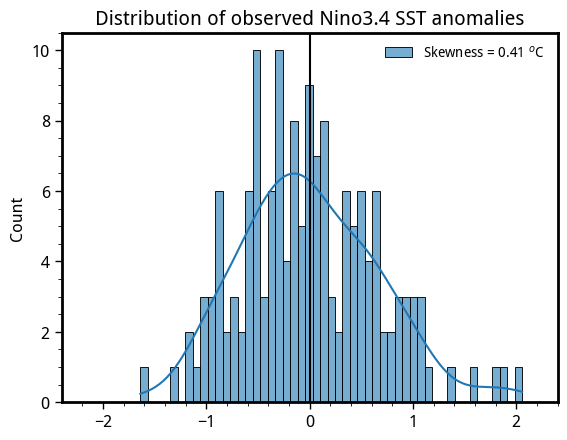

In [13]:
sns.histplot(nino34_obs, bins=51, kde=True, alpha=0.6, color='tab:blue', label=f'Skewness = {np.round(stats.skew(nino34_obs), 3)} $^o$C')
plt.axvline(0.0, color='k', ls='-')
plt.xlim(-2.4, 2.4)
plt.minorticks_on()
plt.title('Distribution of observed Nino3.4 SST anomalies')
plt.legend(frameon=False, fontsize=10)

[Text(1, 0, 'strong-LN'),
 Text(2, 0, 'LN'),
 Text(3, 0, 'NEUT'),
 Text(4, 0, 'EN'),
 Text(5, 0, 'strong-EN')]

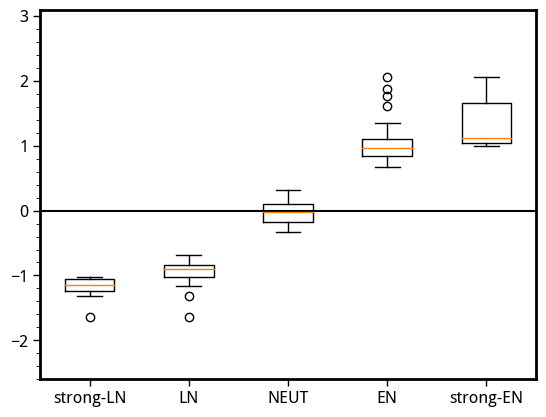

In [14]:
thres = nino34_obs.std('time')
plt.boxplot([nino34_obs.where(nino34_obs < -1.5*thres, drop=True),
             nino34_obs.where(nino34_obs < -thres, drop=True),
             nino34_obs.where((nino34_obs > -0.5*thres) & (nino34_obs < 0.5*thres), drop=True),
             nino34_obs.where(nino34_obs > thres, drop=True),
             nino34_obs.where(nino34_obs > 1.5*thres, drop=True)])


plt.ylim(-2.6, 3.1)
plt.axhline(0.0, color='k', ls='-')
plt.minorticks_on()
plt.tick_params(axis='x', which='minor', bottom=False)
plt.gca().set_xticklabels(['strong-LN', 'LN', 'NEUT', 'EN', 'strong-EN'])

In [15]:
import regionmask

In [16]:
land_mask = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(precip_obs)
ar6_mask = regionmask.defined_regions.ar6.land.mask_3D(precip_obs.where(land_mask))

In [17]:
precip_obs_anom = funcs.calc_anom(precip_obs, precip_obs.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time')

In [18]:
weights_precip_obs = np.cos(np.deg2rad(precip_obs.lat))
reg_anom = precip_obs_anom.where(ar6_mask.isel(region=15)).weighted(weights_precip_obs).mean(('lat', 'lon'))

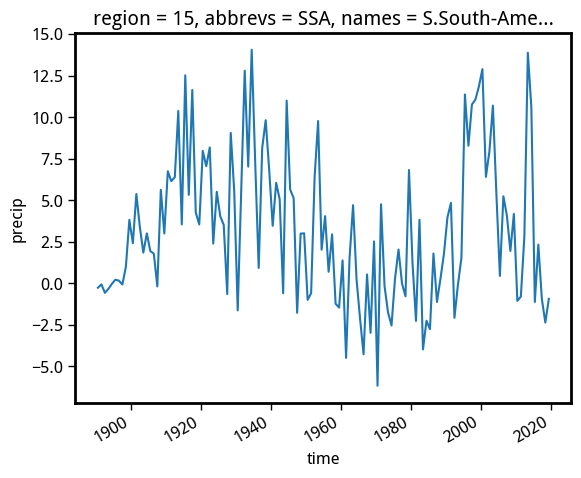

In [19]:
reg_anom.plot()

In [20]:
reg_det = funcs.detrend_separate_check(reg_anom, dim='time', period=15)
reg_std = reg_det/reg_det.std('time')

In [21]:
reg_std = reg_std.sel(time = slice('1900', '2014'))
nino34_obs = nino34_obs.sel(time = slice('1900', '2014'))
reg_std['time'] = nino34_obs['time']

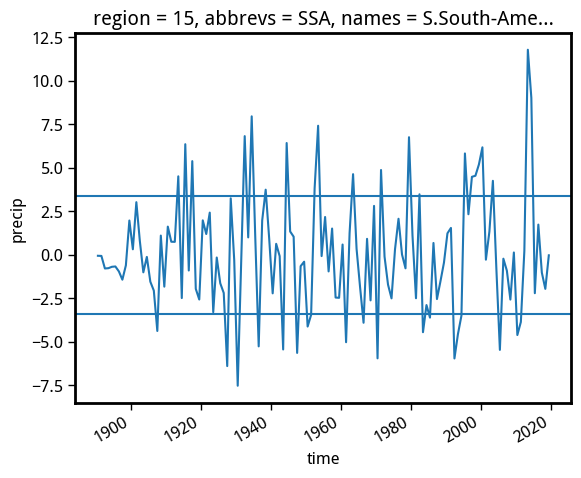

In [22]:
reg_det.plot()
plt.axhline(reg_det.std())
plt.axhline(-reg_det.std())

In [23]:
def calc_tele(precip: xr.DataArray, nino34: xr.DataArray, start_year: int, end_year: int):
    if not isinstance(precip, xr.DataArray) or not isinstance(nino34, xr.DataArray):
        raise TypeError("'xr.DataArray' input is required, not the %s" % (type(precip)))
    duration = end_year - start_year
    res = stats.linregress(nino34.sel(time=slice(str(start_year), str(end_year))), precip.sel(time=slice(str(start_year), str(end_year))))
    return res.slope, res.pvalue, duration


def get_all_tele(precip: xr.DataArray, nino34: xr.DataArray, initial_dur: int = 10):
    if not isinstance(precip, xr.DataArray) or not isinstance(nino34, xr.DataArray):
        raise TypeError("'xr.DataArray' input is required, not the %s" % (type(precip)))
    start_years = np.arange(1900, 2016, 2)
    end_years = np.arange(1900, 2016, 2)
    stat = np.empty((len(start_years), len(end_years)))
    pval = np.empty((len(start_years), len(end_years)))
    duration = np.empty((len(start_years), len(end_years)))
    for i in range(len(start_years)):
        for j in range(len(end_years)):
            if end_years[j] < start_years[i] + initial_dur:
                stat[i, j], pval[i, j], duration[i, j] = np.NaN, np.NaN, np.NaN
            else:
                stat[i, j], pval[i, j], duration[i, j] = calc_tele(precip, nino34, start_years[i], end_years[j])
        # print(f"Completed {start_years[i]}", end='\r')
    return start_years, end_years, stat, pval, duration


In [24]:
calc_tele(reg_std, nino34_obs, start_year=1900, end_year=2014)

(0.06377202603112267, 0.6781742930765542, 114)

In [25]:
# reg_std.to_netcdf('./data/eaus_obs.nc')
# nino34_obs.to_netcdf('./data/nino34_obs.nc')

In [26]:
# funcs.get_regr_1d(nino34_obs.sel(time = slice('1900', '2000')), reg_std.sel(time = slice('1900', '2000')))

In [27]:
sy, ey, sl, p, dur = get_all_tele(reg_std, nino34_obs, initial_dur=30)

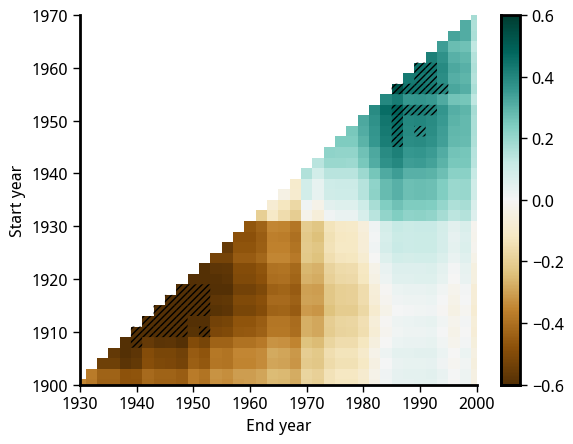

In [128]:
x, y = np.meshgrid(ey, sy)
cf = plt.pcolormesh(ey, sy, sl, cmap='BrBG', vmin=-0.6, vmax=0.6)
z = np.ma.masked_greater(p, 0.05)
plt.pcolor(x,y, z, hatch='/////', alpha=0.)
plt.colorbar(cf)
sns.despine()
# plt.gca().invert_yaxis()
plt.gca().invert_xaxis()
plt.ylabel('Start year')
plt.xlabel('End year')
plt.xlim(1930, 2000)
plt.ylim(1900, 1970)
plt.savefig('./images/method/ssa_reg_temporal_tele_variation.png', dpi=300, bbox_inches='tight')

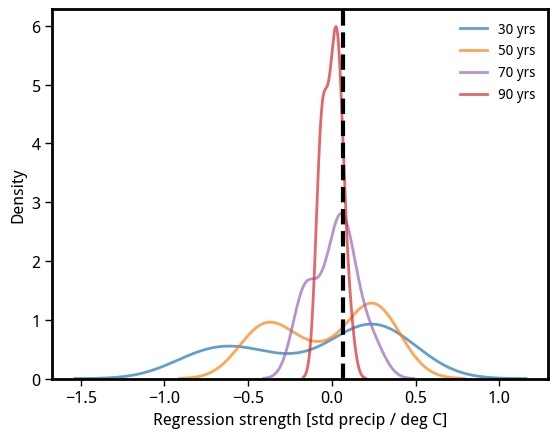

In [129]:
# sns.histplot(sl[dur==30], element='step', kde=True, bins=31, alpha=0.3, color='tab:blue', label='30 yrs')
# sns.histplot(sl[dur==50], element='step', kde=True, bins=31, alpha=0.3, color='tab:orange', label='50 yrs')
# sns.histplot(sl[dur==70], element='step', kde=True, bins=31, alpha=0.3, color='tab:purple', label='70 yrs')
# sns.histplot(sl[dur==90], element='step', kde=True, bins=31, alpha=0.3, color='tab:red', label='90 yrs')
# plt.axvline(sl[dur==100], color='k', ls='--', lw=3.0)

sns.kdeplot(sl[dur==30], alpha=0.7, lw=2.0, color='tab:blue', label='30 yrs')
sns.kdeplot(sl[dur==50], alpha=0.7, lw=2.0, color='tab:orange', label='50 yrs')
sns.kdeplot(sl[dur==70], alpha=0.7, lw=2.0, color='tab:purple', label='70 yrs')
sns.kdeplot(sl[dur==90], alpha=0.7, lw=2.0, color='tab:red', label='90 yrs')
plt.axvline(sl[dur==114], color='k', ls='--', lw=3.0)
plt.legend(frameon=False, fontsize=10)
plt.xlabel('Regression strength [std precip / deg C]')
# plt.title('N. Australia [OBS]')

plt.savefig('./images/method/ssa_reg_sample_size_effects.png', dpi=300, bbox_inches='tight')

In [30]:
np.std(sl[dur==30]), np.std(sl[dur==90])

(0.44124912684233575, 0.05226098065834452)

In [31]:
np.shape(sl[dur==30])

(43,)

In [32]:
np.max(sl[dur==30]), np.min(sl[dur==30])

(0.5270673207523091, -0.9027294242507429)

In [38]:
def calc_tele_diversity(precip_std, nino34, duration=30, gap=2):
    if np.nansum(precip_std) != 0:
        i = 0
        regr_arr = []
        pval_arr = []
        ey=[]
        while i < (len(precip_std.time) - duration):
            regr_arr.append(funcs.get_regr(nino34.isel(time = slice(i,i+duration)), precip_std.isel(time=slice(i,i+duration)), dim='time').data)
            pval_arr.append(funcs.get_pval(nino34.isel(time = slice(i,i+duration)), precip_std.isel(time=slice(i,i+duration)), dim='time').data)
            ey.append(float(nino34.time.dt.year[i+duration]))
            print(f'Completed ey: {float(nino34.time.dt.year[i+duration])}', end='\r')
            i += gap

        out30 = xr.Dataset(
            data_vars=dict(
                regr=(["ey", "lat", "lon"], np.concatenate([arr[np.newaxis, ...] for arr in regr_arr])),
                pval=(["ey", "lat", "lon"], np.concatenate([arr[np.newaxis, ...] for arr in pval_arr])),
            ),
            coords=dict(
                lon = ("lon", precip_std.lon.to_numpy()),
                lat = ("lat", precip_std.lat.to_numpy()),
                ey = ("ey", ey),
            ),
            )

        return out30

In [36]:
precip_obs_det = funcs.detrend_separate_check(precip_obs_anom, dim='time', period=15)
precip_obs_std = precip_obs_det/precip_obs_det.std()

In [59]:
precip_rean_anom = funcs.calc_anom(precip_rean, precip_rean.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time')

In [60]:
precip_rean_det = funcs.detrend_separate_check(precip_rean_anom, dim='time', period=15)
precip_rean_std = precip_rean_det/precip_rean_det.std()

In [39]:
precip_obs_std = precip_obs_std.sel(time = slice('1900', '2014'))
nino34_obs = nino34_obs.sel(time = slice('1900', '2014'))
precip_obs_std['time'] = nino34_obs['time']

In [61]:
precip_rean_std = precip_rean_std.sel(time = slice('1900', '2014'))
nino34_obs = nino34_obs.sel(time = slice('1900', '2014'))
precip_rean_std['time'] = nino34_obs['time']

In [40]:
long_regr = funcs.get_regr(nino34_obs, precip_obs_std, dim='time')
long_pval = funcs.get_pval(nino34_obs, precip_obs_std, dim='time')

In [81]:
long_regr_rean = funcs.get_regr(nino34_obs, precip_rean_std.prate, dim='time')
long_pval_rean = funcs.get_pval(nino34_obs, precip_rean_std.prate, dim='time')

In [41]:
out30 = calc_tele_diversity(precip_obs_std, nino34_obs, duration=30, gap=2)

In [75]:
out30_rean = calc_tele_diversity(precip_rean_std.prate, nino34_obs, duration=30, gap=2)

In [42]:
out30

<xarray.Dataset>
Dimensions:  (ey: 43, lat: 180, lon: 360)
Coordinates:
  * lon      (lon) float32 0.5 1.5 2.5 3.5 4.5 ... 355.5 356.5 357.5 358.5 359.5
  * lat      (lat) float32 89.5 88.5 87.5 86.5 85.5 ... -86.5 -87.5 -88.5 -89.5
  * ey       (ey) float64 1.93e+03 1.932e+03 1.934e+03 ... 2.012e+03 2.014e+03
Data variables:
    regr     (ey, lat, lon) float64 nan nan nan nan nan ... nan nan nan nan nan
    pval     (ey, lat, lon) float64 nan nan nan nan nan ... nan nan nan nan nan

In [43]:
out30.to_netcdf('./data/out30.nc')

In [76]:
out30_rean.to_netcdf('./data/out30_rean.nc')

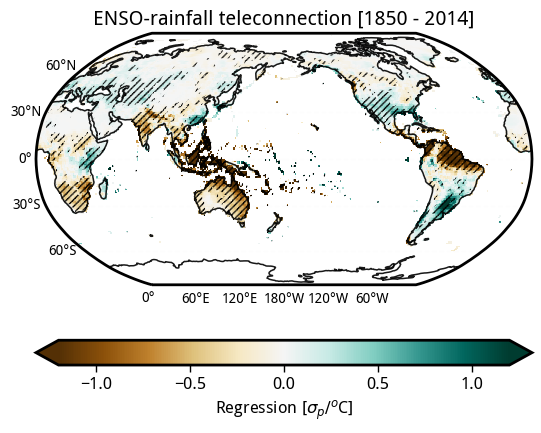

In [108]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
long_regr.plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
xx, yy = np.meshgrid(long_pval.lon, long_pval.lat)
zz = np.ma.masked_greater_equal(long_pval.data, 0.05)
plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plt.title('ENSO-rainfall teleconnection [1850 - 2014]')
plot_background(ax)
# ax.text(0.1, 0.9, 'a', fontsize=20)
# ax.coastlines()
# gl = ax.gridlines(alpha=0., draw_labels=True)
# gl.top_labels=False
# gl.right_labels=False
plt.savefig('./images/long_regr_obs.png', dpi=300, bbox_inches='tight')

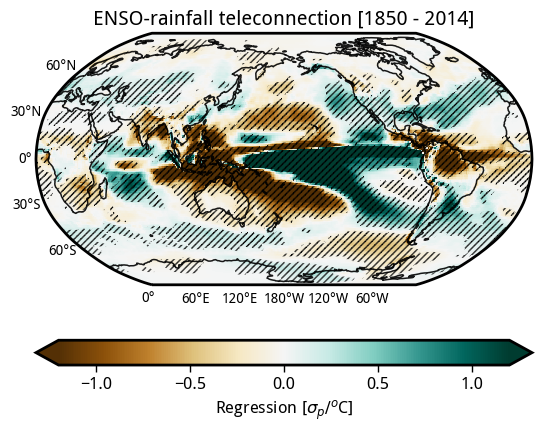

In [109]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
long_regr_rean.plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
xx, yy = np.meshgrid(long_pval_rean.lon, long_pval_rean.lat)
zz = np.ma.masked_greater_equal(long_pval_rean.data, 0.05)
plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plt.title('ENSO-rainfall teleconnection [1850 - 2014]')
plot_background(ax)
# ax.text(0.1, 0.9, 'a', fontsize=20)
plt.savefig('./images/long_regr_rean.png', dpi=300, bbox_inches='tight')

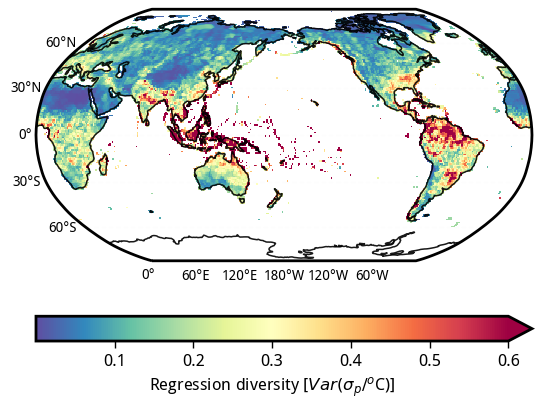

In [110]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30.regr.std('ey').plot(vmax=0.6, cmap='Spectral_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression diversity [$Var(\sigma_{p}/^{o}$C)]'))
plot_background(ax)
plt.savefig('./images/variance_regr_30y.png', dpi=300, bbox_inches='tight')

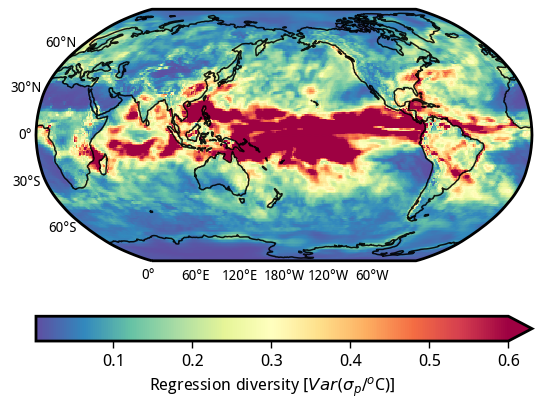

In [111]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30_rean.regr.std('ey').plot(vmax=0.6, cmap='Spectral_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression diversity [$Var(\sigma_{p}/^{o}$C)]'))
plot_background(ax)
plt.savefig('./images/variance_regr_30y_rean.png', dpi=300, bbox_inches='tight')

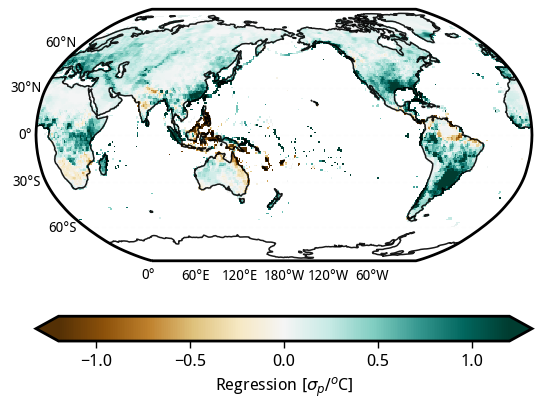

In [112]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30.regr.max('ey').plot(vmax=1.2, cmap='BrBG', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/max_regr_30y.png', dpi=300, bbox_inches='tight')

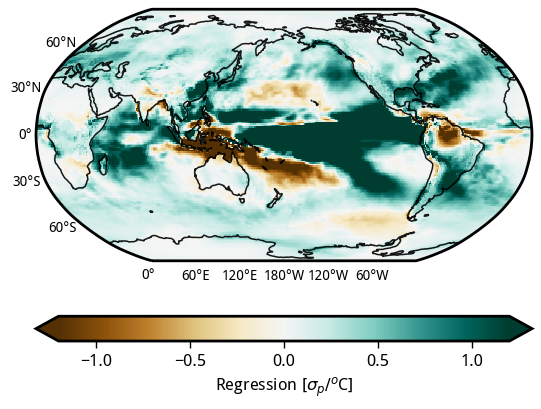

In [113]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30_rean.regr.max('ey').plot(vmax=1.2, cmap='BrBG', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/max_regr_30y_rean.png', dpi=300, bbox_inches='tight')

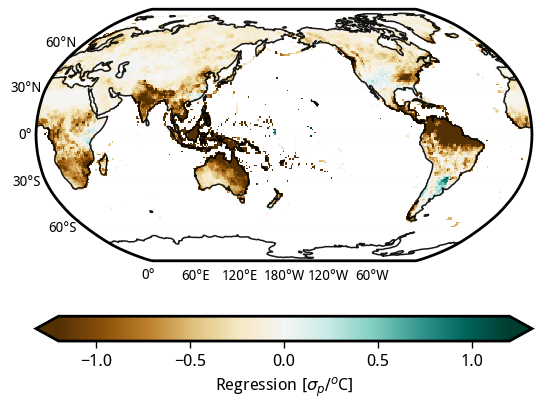

In [120]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30.regr.min('ey').plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/min_regr_30y.png', dpi=300, bbox_inches='tight')

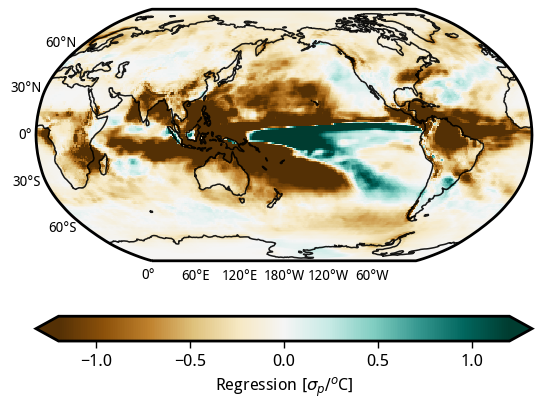

In [121]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30_rean.regr.min('ey').plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/min_regr_30y_rean.png', dpi=300, bbox_inches='tight')

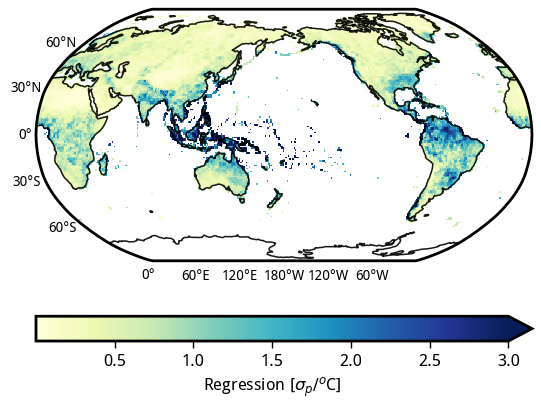

In [124]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(out30.regr.max('ey') - out30.regr.min('ey')).plot(vmax=3, cmap='YlGnBu', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

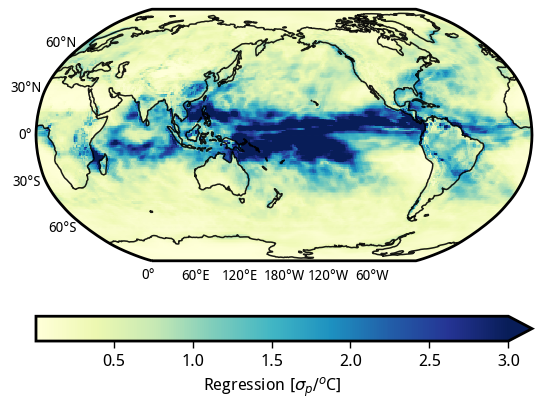

In [125]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(out30_rean.regr.max('ey') - out30_rean.regr.min('ey')).plot(vmax=3, cmap='YlGnBu', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/range_regr_30y_rean.png', dpi=300, bbox_inches='tight')

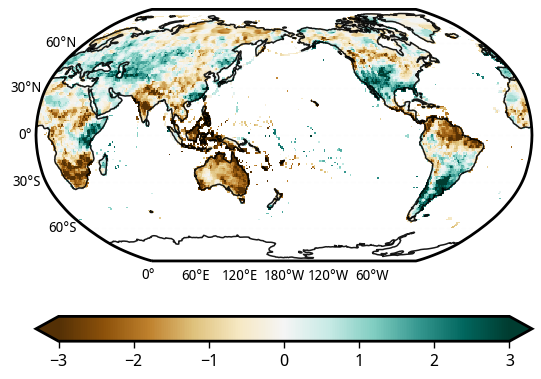

In [126]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(long_regr/out30.regr.std('ey')).plot(vmin=-3.0, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label=''))
plot_background(ax)
plt.savefig('./images/long_regr_location_context.png', dpi=300, bbox_inches='tight')

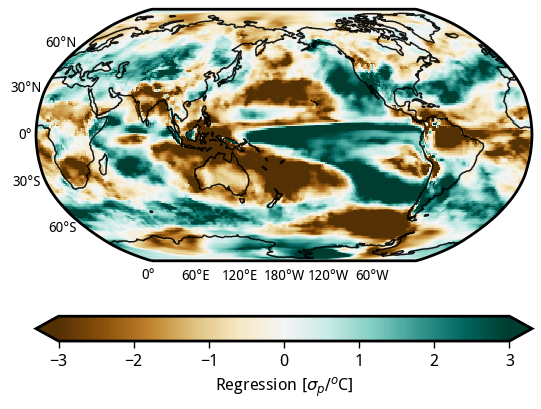

In [127]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(long_regr_rean/out30_rean.regr.std('ey')).plot(vmin=-3.0, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/long_regr_location_context_rean.png', dpi=300, bbox_inches='tight')

#### Potential TODOs


- breaking this thing down to regions and plotting the max, min, std and context for each IPCC region to get more ideas on a regional context

#### The plot below highlights that the ENSO-rainfall variabilty on shorter term is remarkably similar to the local rainfall variability

ENSO is perhaps a key factor responsible for long term rainfall variability in these key regions

<GeoAxesSubplot:xlabel='Longitude [degrees_east]', ylabel='Latitude [degrees_north]'>

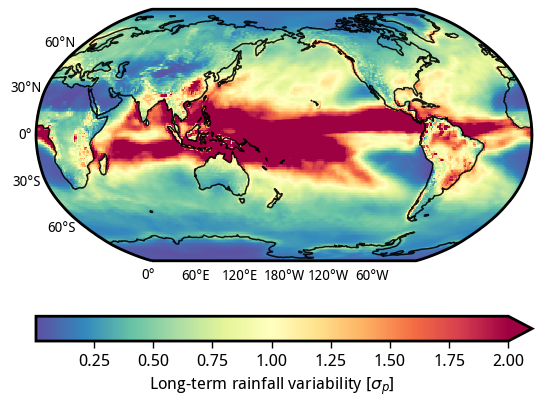

In [280]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(precip_rean_std.prate.std('time')).plot(vmax=2, cmap='Spectral_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Long-term rainfall variability [$\sigma_{p}$]'))
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

**Timing of the peaks**

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

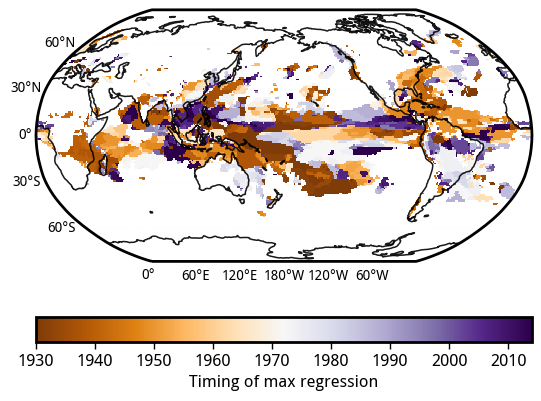

In [281]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(out30_rean.regr.ey.where((out30_rean.regr == out30_rean.regr.min('ey')) & (out30_rean.regr.std('ey') > 0.20)).mean('ey')).plot(cmap='PuOr', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Timing of max regression'), robust=True)
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

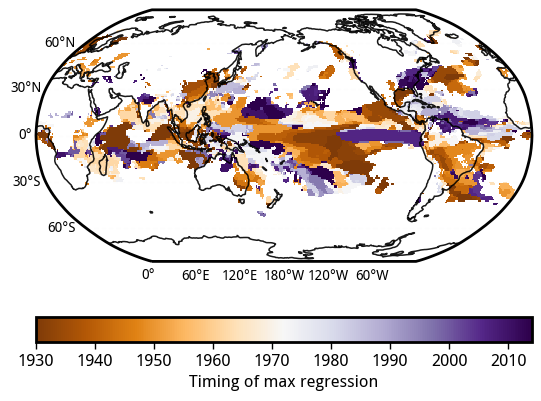

In [282]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(out30_rean.regr.ey.where((out30_rean.regr == out30_rean.regr.max('ey')) & (out30_rean.regr.std('ey') > 0.20)).mean('ey')).plot(cmap='PuOr', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Timing of max regression'), robust=True)
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

In [214]:
def calc_windowed_tpi_strength(tpi_index, duration=30, gap=2):
    if np.nansum(tpi_index) != 0:
        i = 0
        tpi_out = []
        ey=[]
        while i < (len(tpi_index.time) - duration):
            tpi_out.append(tpi_index.isel(time=slice(i,i+duration)).mean('time').data)
            ey.append(float(tpi_index.time.dt.year[i+duration]))
            print(f'Completed ey: {float(tpi_index.time.dt.year[i+duration])}', end='\r')
            i += gap

        out = xr.Dataset(
            data_vars=dict(
                tpi=(["ey"], np.concatenate([arr[np.newaxis, ...] for arr in tpi_out])),
            ),
            coords=dict(
                ey = ("ey", ey),
            ),
            )

        return out

In [228]:
tpi_da = xr.open_dataset('./data/tpi.nc')
tpi_windows = calc_windowed_tpi_strength(tpi_da.TPI_unfil.resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014')), duration=30, gap=2)

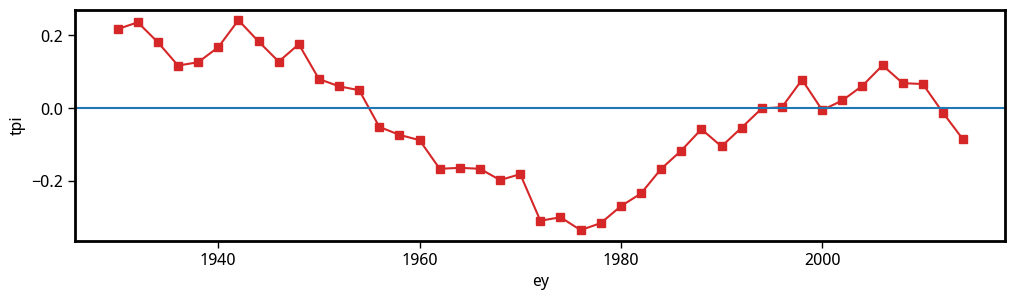

In [229]:
plt.figure(figsize=(12,3))
# (tpi_da.TPI_unfil).resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014')).plot(color='k', alpha=0.1, lw=1.0)
# (tpi_da.TPI_fil).resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014')).plot(lw=2.0, color='tab:red')
(tpi_windows.tpi).plot(marker='s', color='tab:red')
plt.axhline(0.0)

In [285]:
tpi_tele_corr = funcs.get_corr(tpi_windows.tpi, out30_rean.regr, dim='ey')
tpi_tele_pval = funcs.get_pval(tpi_windows.tpi, out30_rean.regr, dim='ey')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

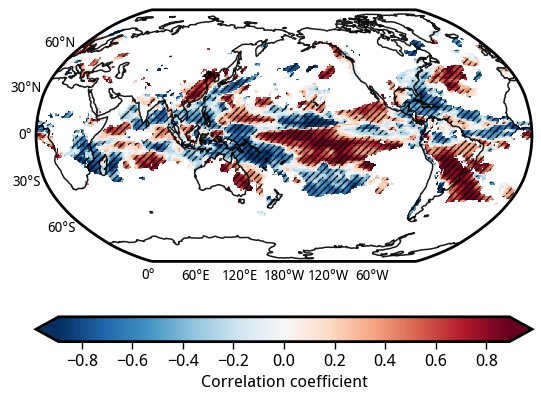

In [286]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(tpi_tele_corr.where((out30_rean.regr.std('ey') > 0.20))).plot(cmap='RdBu_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Correlation coefficient'), robust=True)
xx, yy = np.meshgrid(tpi_tele_corr.lon, tpi_tele_corr.lat)
zz = np.ma.masked_greater_equal(tpi_tele_pval.where((out30_rean.regr.std('ey') > 0.20)).data, 0.05)
plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

In [290]:
long_regr_rean_pre70 = funcs.get_regr(nino34_obs.sel(time = slice('1900', '1970')), precip_rean_std.prate.sel(time = slice('1900', '1970')), dim='time')
long_regr_rean_post80 = funcs.get_regr(nino34_obs.sel(time = slice('1980', '2014')), precip_rean_std.prate.sel(time = slice('1980', '2014')), dim='time')

In [291]:
long_pval_rean_pre70 = funcs.get_pval(nino34_obs.sel(time = slice('1900', '1970')), precip_rean_std.prate.sel(time = slice('1900', '1970')), dim='time')
long_pval_rean_post80 = funcs.get_pval(nino34_obs.sel(time = slice('1980', '2014')), precip_rean_std.prate.sel(time = slice('1980', '2014')), dim='time')

<GeoAxesSubplot:title={'center':'ENSO-rainfall teleconnection [1900 - 1970]'}, xlabel='lon', ylabel='lat'>

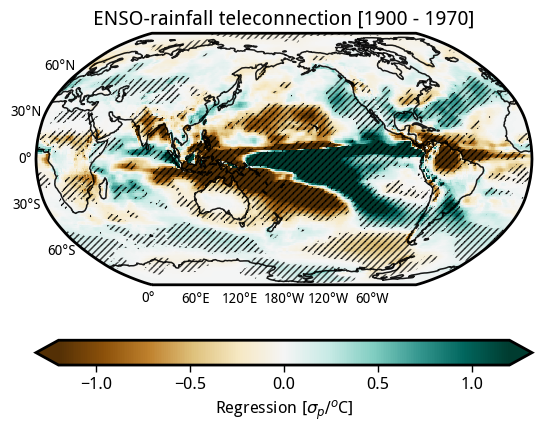

In [292]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
long_regr_rean_pre70.plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
xx, yy = np.meshgrid(long_pval_rean_pre70.lon, long_pval_rean_pre70.lat)
zz = np.ma.masked_greater_equal(long_pval_rean_pre70.data, 0.05)
ax.pcolor(xx, yy, zz, alpha=0., hatch='/////', transform=ccrs.PlateCarree())
plt.title('ENSO-rainfall teleconnection [1900 - 1970]')
plot_background(ax)

<GeoAxesSubplot:title={'center':'ENSO-rainfall teleconnection [1980 - 2014]'}, xlabel='lon', ylabel='lat'>

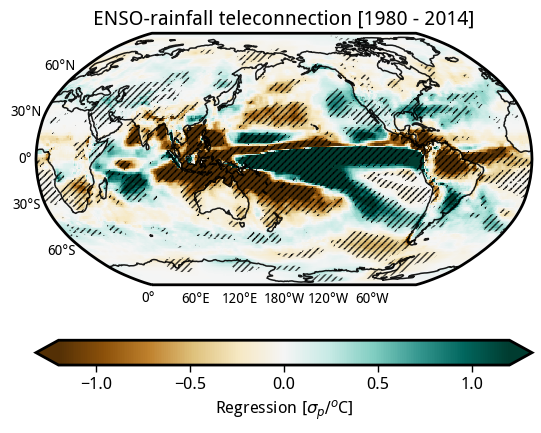

In [293]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
long_regr_rean_post80.plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
# xx, yy = np.meshgrid(long_pval_pre70.lon, long_pval_pre70.lat)
zz = np.ma.masked_greater_equal(long_pval_rean_post80.data, 0.05)
ax.pcolor(xx, yy, zz, alpha=0., hatch='/////', transform=ccrs.PlateCarree())
plt.title('ENSO-rainfall teleconnection [1980 - 2014]')
plot_background(ax)

<GeoAxesSubplot:title={'center':'Difference'}, xlabel='lon', ylabel='lat'>

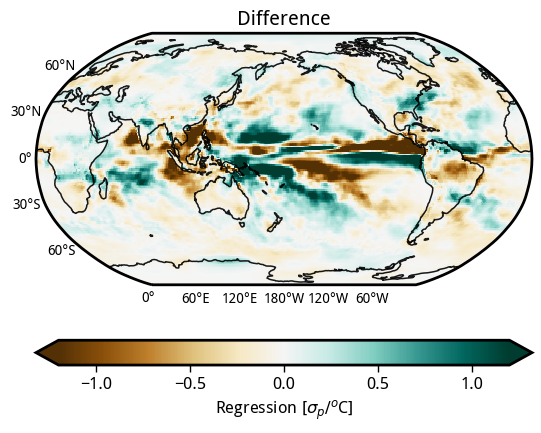

In [295]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(long_regr_rean_post80 - long_regr_rean_pre70).plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plt.title('Difference')
plot_background(ax)

#### import cmip6 hist archive and the access lens hist runs

In [83]:
ts_cmip = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp5.nc').ts.sel(time=slice('1900', '2000')).load()
pr_cmip = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/pr_ssp5.nc').pr.sel(time=slice('1900', '2000'))*86400*30).load()

In [45]:
ts_access = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5_ts.nc').ts.sel(time=slice('1900', '2000')).load()
pr_access = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5_pr.nc').pr.sel(time=slice('1900', '2000'))*86400*30).load()

In [46]:
ts_canesm = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/CanESM5_ssp5_ts.nc').ts.sel(time=slice('1900', '2000')).load()
pr_canesm = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/CanESM5_ssp5_pr.nc').pr.sel(time=slice('1900', '2000'))*86400*30).load()

In [47]:
weights_model = np.cos(np.deg2rad(ts_cmip.lat))

ts_cmip_anom = funcs.calc_anom(ts_cmip, ts_cmip.sel(time = slice('1960', '1990')))
nino34_cmip = funcs.detrend_separate_check(ts_cmip_anom.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_model).mean(('lat', 'lon')), dim='time', period=15)

In [48]:
ts_access_anom = funcs.calc_anom(ts_access, ts_access.sel(time = slice('1960', '1990')))
nino34_access = funcs.detrend_separate_check(ts_access_anom.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_model).mean(('lat', 'lon')), dim='time', period=15)

In [49]:
ts_canesm_anom = funcs.calc_anom(ts_canesm, ts_canesm.sel(time = slice('1960', '1990')))
nino34_canesm = funcs.detrend_separate_check(ts_canesm_anom.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_model).mean(('lat', 'lon')), dim='time', period=15)

In [84]:
land_mask_model = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(pr_cmip)
ar6_mask_model = regionmask.defined_regions.ar6.land.mask_3D(land_mask_model)

reg_anom_cmip = pr_cmip.where(ar6_mask_model.isel(region=39)).weighted(weights_model).mean(('lat', 'lon'))
reg_anom_access = pr_access.where(ar6_mask_model.isel(region=39)).weighted(weights_model).mean(('lat', 'lon'))
reg_anom_canesm = pr_canesm.where(ar6_mask_model.isel(region=39)).weighted(weights_model).mean(('lat', 'lon'))

In [85]:
reg_det_cmip = funcs.detrend_separate_check(reg_anom_cmip, dim='time', period=15)
reg_det_access = funcs.detrend_separate_check(reg_anom_access, dim='time', period=15)
reg_det_canesm = funcs.detrend_separate_check(reg_anom_canesm, dim='time', period=15)

reg_std_cmip = reg_det_cmip/reg_det_cmip.std('time')
reg_std_access = reg_det_access/reg_det_access.std('time')
reg_std_canesm = reg_det_canesm/reg_det_canesm.std('time')

In [86]:
sym, eym, slm, pm, durm = get_all_tele(reg_std_cmip.isel(model=0), nino34_cmip.isel(model=0), initial_dur=30)
sya, eya, sla, pa, dura = get_all_tele(reg_std_access.isel(model=0), nino34_access.isel(model=0), initial_dur=30)
syc, eyc, slc, pc, durc = get_all_tele(reg_std_canesm.isel(model=0), nino34_canesm.isel(model=0), initial_dur=30)

Text(0.5, 1.0, 'Random CMIP model')

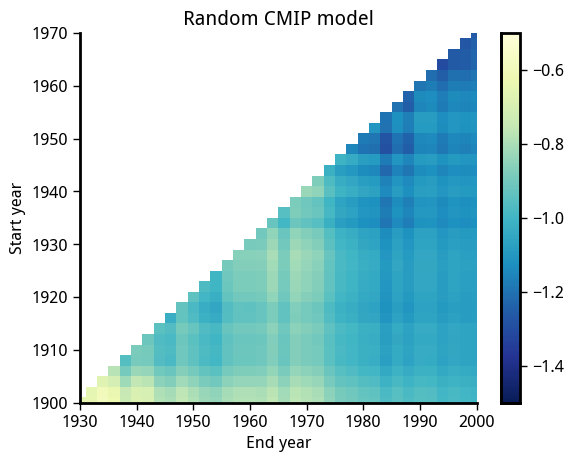

In [88]:
x, y = np.meshgrid(eym, sym,)
cf = plt.pcolormesh(eym, sym, slm, cmap='YlGnBu_r', vmin=-1.5, vmax=-0.5)
z = np.ma.masked_less_equal(pm, 0.05)
plt.pcolor(x,y, z, hatch='/////', alpha=0.)
plt.colorbar(cf)
sns.despine()
# plt.gca().invert_yaxis()
# plt.gca().invert_xaxis()
plt.ylabel('Start year')
plt.xlabel('End year')
plt.xlim(1930, 2000)
plt.ylim(1900, 1970)
plt.title('Random CMIP model')

Text(0.5, 1.0, 'Random ACCESS-ESM1-5 hist run')

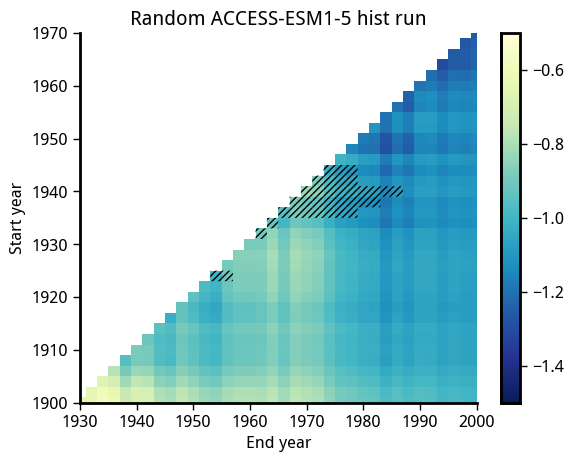

In [89]:
x, y = np.meshgrid(eya, sya)
cf = plt.pcolormesh(eym, sym, slm, cmap='YlGnBu_r', vmin=-1.5, vmax=-0.5)
z = np.ma.masked_less_equal(pa, 0.05)
plt.pcolor(x,y, z, hatch='/////', alpha=0.)
plt.colorbar(cf)
sns.despine()
# plt.gca().invert_yaxis()
# plt.gca().invert_xaxis()
plt.ylabel('Start year')
plt.xlabel('End year')
plt.xlim(1930, 2000)
plt.ylim(1900, 1970)
plt.title('Random ACCESS-ESM1-5 hist run')

Text(0.5, 1.0, 'Random CanESM5 hist run')

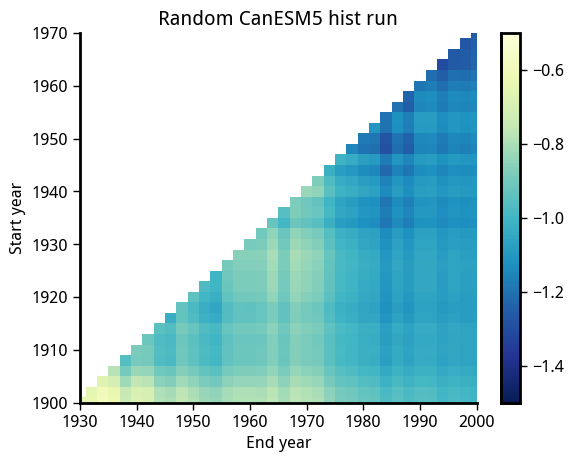

In [90]:
x, y = np.meshgrid(eyc, syc)
cf = plt.pcolormesh(eym, sym, slm, cmap='YlGnBu_r', vmin=-1.5, vmax=-0.5)
z = np.ma.masked_less_equal(pc, 0.05)
plt.pcolor(x,y, z, hatch='/////', alpha=0.)
plt.colorbar(cf)
sns.despine()
# plt.gca().invert_yaxis()
# plt.gca().invert_xaxis()
plt.ylabel('Start year')
plt.xlabel('End year')
plt.xlim(1930, 2000)
plt.ylim(1900, 1970)
plt.title('Random CanESM5 hist run')

Text(0.5, 1.0, '100 years')

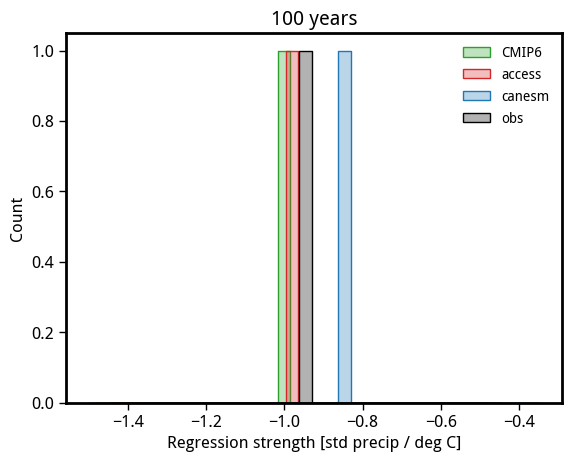

In [91]:
sns.histplot(slm[durm==100], element='step', kde=True, bins=31, alpha=0.3, color='tab:green', label='CMIP6')
sns.histplot(sla[dura==100], element='step', kde=True, bins=31, alpha=0.3, color='tab:red', label='access')
sns.histplot(slc[durc==100], element='step', kde=True, bins=31, alpha=0.3, color='tab:blue', label='canesm')
sns.histplot(sl[dur==100], element='step', kde=True, bins=31, alpha=0.3, color='k', label='obs')
# sns.histplot(slm[durm==50], kde=True, bins=31, alpha=0.3, color='tab:orange', label='50 yrs')
# sns.histplot(slm[durm==70], kde=True, bins=31, alpha=0.3, color='tab:purple', label='70 yrs')
# sns.histplot(slm[durm==90], kde=True, bins=31, alpha=0.3, color='tab:red', label='90 yrs')
plt.legend(frameon=False, fontsize=10)
plt.xlabel('Regression strength [std precip / deg C]')
plt.title('100 years')


**summarizing -**

- ENSO changes significantly over the course of the 20th century using shorter temporal windows of 30 years.
- Over the period of 100 years, models have some disagreements in teleconnection strenght due to inherent biases
- We can use the 100 year overlaps and differences to understand simulated teleconnections in the long-term and also use the observed 30 year teleconnections to understand present and future teleconnection changes in shorter temporal windows

Text(0.5, 1.0, '30 years')

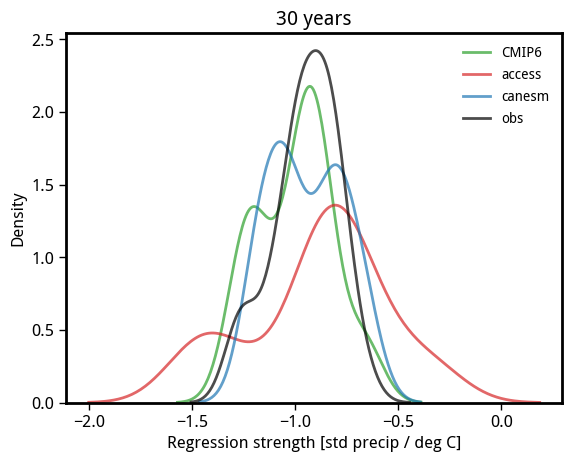

In [93]:
# sns.histplot(slm[durm==30], element='step', kde=True, bins=31, alpha=0.2, color='tab:green', label='CMIP6')
# sns.histplot(sla[dura==30], element='step', kde=True, bins=31, alpha=0.2, color='tab:red', label='access')
# sns.histplot(slc[durc==30], element='step', kde=True, bins=31, alpha=0.2, color='tab:blue', label='canesm')
# sns.histplot(sl[dur==30], element='step', kde=True, bins=31, alpha=0.2, color='k', label='obs')

sns.kdeplot(slm[durm==30], alpha=0.7, lw=2.0, color='tab:green', label='CMIP6')
sns.kdeplot(sla[dura==30], alpha=0.7, lw=2.0, color='tab:red', label='access')
sns.kdeplot(slc[durc==30], alpha=0.7, lw=2.0, color='tab:blue', label='canesm')
sns.kdeplot(sl[dur==30], alpha=0.7, lw=2.0, color='k', label='obs')
plt.legend(frameon=False, fontsize=10)
plt.xlabel('Regression strength [std precip / deg C]')
plt.title('30 years')

In [95]:
nino34_cmip

<xarray.DataArray 'ts' (model: 47, time: 101)>
array([[-0.07410232, -0.45429978, -0.20289085, ..., -0.13887925,
         0.25904961,  1.67396609],
       [-0.07410232, -0.45429978, -0.20289085, ..., -0.13887925,
         0.25904961,  1.67396609],
       [-1.10552318, -0.7095763 ,  0.94394343, ..., -0.75806055,
        -1.03638841, -0.65357911],
       ...,
       [-1.51699016, -0.52118682,  1.78261858, ..., -1.1486678 ,
        -1.0080636 ,  0.45320802],
       [ 0.87946661, -1.11779526, -0.19194304, ...,  0.98617974,
        -0.98832931,  0.33112582],
       [ 0.365005  , -0.63020674, -0.21390788, ..., -0.77924636,
         0.03912276,  0.81344535]])
Coordinates:
  * time     (time) datetime64[ns] 1900-06-01 1901-06-01 ... 2000-06-01
  * model    (model) object 'CanESM5' 'CanESM5-CanOE' ... 'BCC-CSM2-MR'
    month    (time) int64 6 6 6 6 6 6 6 6 6 6 6 6 6 ... 6 6 6 6 6 6 6 6 6 6 6 6

In [96]:
reg_std_cmip['model'] = nino34_cmip.drop_sel(model='KIOST-ESM')['model']
reg_std_access['model'] = nino34_access['model']
reg_std_canesm['model'] = nino34_canesm['model']

Text(0.5, 1.0, '100 years internal variability')

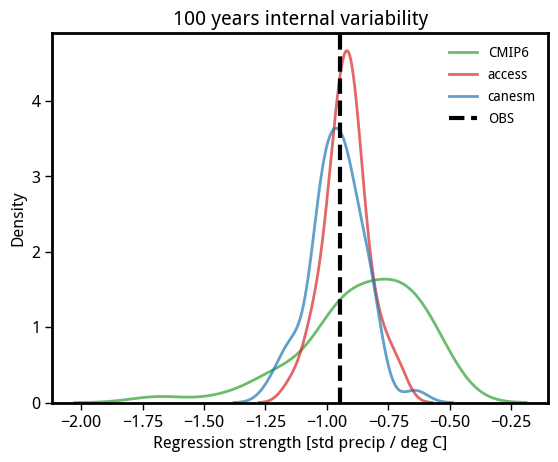

In [97]:
# sns.histplot(funcs.get_regr(nino34_cmip.sel(time = slice('1900', '2000')).drop_sel(model='KIOST-ESM'), reg_std_cmip.sel(time = slice('1900', '2000')), dim='time'), element='step', kde=True, bins=31, alpha=0.3, color='tab:green', label='CMIP6')
# sns.histplot(funcs.get_regr(nino34_access.sel(time = slice('1900', '2000')), reg_std_access.sel(time = slice('1900', '2000')), dim='time'), element='step', kde=True, bins=31, alpha=0.3, color='tab:red', label='access')
# sns.histplot(funcs.get_regr(nino34_canesm.sel(time = slice('1900', '2000')), reg_std_canesm.sel(time = slice('1900', '2000')), dim='time'), element='step', kde=True, bins=31, alpha=0.3, color='tab:blue', label='canesm')
# plt.axvline(funcs.get_regr_1d(nino34_obs.sel(time = slice('1900', '2000')), reg_std.sel(time = slice('1900', '2000'))), color='k', lw=3.0, ls='--', label='OBS')

sns.kdeplot(funcs.get_regr(nino34_cmip.sel(time = slice('1900', '2000')).drop_sel(model='KIOST-ESM'), reg_std_cmip.sel(time = slice('1900', '2000')), dim='time'), alpha=0.7, lw=2.0, color='tab:green', label='CMIP6')
sns.kdeplot(funcs.get_regr(nino34_access.sel(time = slice('1900', '2000')), reg_std_access.sel(time = slice('1900', '2000')), dim='time'), alpha=0.7, lw=2.0, color='tab:red', label='access')
sns.kdeplot(funcs.get_regr(nino34_canesm.sel(time = slice('1900', '2000')), reg_std_canesm.sel(time = slice('1900', '2000')), dim='time'), alpha=0.7, lw=2.0, color='tab:blue', label='canesm')
plt.axvline(funcs.get_regr_1d(nino34_obs.sel(time = slice('1900', '2000')), reg_std.sel(time = slice('1900', '2000'))), color='k', lw=3.0, ls='--', label='OBS')
plt.legend(frameon=False, fontsize=10)
plt.xlabel('Regression strength [std precip / deg C]')
plt.title('100 years internal variability')